In [3]:
import pandas as pd
print(pd.__version__)


3.0.6


In [2]:
import sys
print(sys.executable)

c:\Users\D Sahasra\OneDrive\Desktop\Sales_Performance_Analytic_Dashboard_Project\.venv\Scripts\python.exe


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("Sales Performance Analytics")
print("My project is ready!")

Sales Performance Analytics
My project is ready!


## Sales Data Cleaning and Preprocessing

## Objective
The objective of this phase is to inspect the raw sales dataset,
identify data quality issues, clean the data where necessary,
standardize dates and text, validate numerical values, and save
a cleaned dataset for further analysis.

## Dataset
Source: Kaggle
File: sample_sales_data.csv

In [5]:
import pandas as pd
df = pd.read_csv("../data/Superstore.csv")
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,7981,CA-2011-103800,04-01-2011,08-01-2011,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,77095,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512
1,740,CA-2011-112326,05-01-2011,09-01-2011,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717
2,741,CA-2011-112326,05-01-2011,09-01-2011,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748
3,742,CA-2011-112326,05-01-2011,09-01-2011,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,60540,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870
4,1760,CA-2011-141817,06-01-2011,13-01-2011,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,19143,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840


In [6]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

In [7]:
df.shape


(9994, 21)

In [8]:
df.describe()

,Row ID,Postal Code,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000,9994.000000
mean,4997.500000,55190.379428,229.858001,3.789574,0.156203,28.656896
std,2885.163629,32063.693350,623.245101,2.225110,0.206452,234.260108
min,1.000000,1040.000000,0.444000,1.000000,0.000000,-6599.978000
25%,2499.250000,23223.000000,17.280000,2.000000,0.000000,1.728750
50%,4997.500000,56430.500000,54.490000,3.000000,0.200000,8.666500
75%,7495.750000,90008.000000,209.940000,5.000000,0.200000,29.364000
max,9994.000000,99301.000000,22638.480000,14.000000,0.800000,8399.976000


In [9]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Customer Name',
 'Segment',
 'Country',
 'City',
 'State',
 'Postal Code',
 'Region',
 'Product ID',
 'Category',
 'Sub-Category',
 'Product Name',
 'Sales',
 'Quantity',
 'Discount',
 'Profit']

In [10]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
dtype: int64

In [11]:
df.isnull().sum()[df.isnull().sum() > 0]

Series([], dtype: int64)

In [12]:
df.duplicated().sum()

np.int64(0)

In [13]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"], errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"], errors="coerce"
)

df[["Order Date", "Ship Date"]].head()

,Order Date,Ship Date
0,2011-04-01,2011-08-01
1,2011-05-01,2011-09-01
2,2011-05-01,2011-09-01
3,2011-05-01,2011-09-01
4,2011-06-01,NaT


In [14]:
raw_df = pd.read_csv("../data/Superstore.csv")
raw_df.loc[4, ["Order Date", "Ship Date"]]

Order Date    06-01-2011
Ship Date     13-01-2011
Name: 4, dtype: str

In [15]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

In [16]:
df.loc[4, ["Order Date", "Ship Date"]]

Order Date   2011-06-01
Ship Date           NaT
Name: 4, dtype: datetime64[us]

In [18]:
raw_df = pd.read_csv("../data/Superstore.csv")
print(repr(raw_df.loc[4, "Order Date"]))
print(repr(raw_df.loc[4, "Ship Date"]))
print(raw_df[["Order Date", "Ship Date"]].head(10))

'06-01-2011'
'13-01-2011'
   Order Date   Ship Date
0  04-01-2011  08-01-2011
1  05-01-2011  09-01-2011
2  05-01-2011  09-01-2011
3  05-01-2011  09-01-2011
4  06-01-2011  13-01-2011
5  07-01-2011  09-01-2011
6  07-01-2011  08-01-2011
7  07-01-2011  11-01-2011
8  07-01-2011  11-01-2011
9  07-01-2011  11-01-2011


In [20]:
df = raw_df.copy()
df["Order Date"] = pd.to_datetime(
    df["Order Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)
df["Ship Date"] = pd.to_datetime(
    df["Ship Date"].astype("string").str.strip(),
    format="%d-%m-%Y",
    errors="coerce"
)
df.loc[4, ["Order Date", "Ship Date"]]

Order Date   2011-01-06
Ship Date    2011-01-13
Name: 4, dtype: datetime64[us]

In [21]:
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

Invalid Order Dates: 0
Invalid Ship Dates: 0


In [22]:
df.loc[4, ["Order Date", "Ship Date"]]

Order Date   2011-01-06
Ship Date    2011-01-13
Name: 4, dtype: datetime64[us]

In [25]:
print(df.columns.tolist())

['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit']


In [26]:
text_columns = [
    "Category",
    "Sub-Category",
    "Segment",
    "Region",
    "Ship Mode",
    "Country",
    "State",
    "City"
]

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

In [27]:
print("Categories:", df["Category"].unique())
print("Regions:", df["Region"].unique())
print("Ship Modes:", df["Ship Mode"].unique())

Categories: <StringArray>
['Office Supplies', 'Furniture', 'Technology']
Length: 3, dtype: str
Regions: <StringArray>
['Central', 'East', 'West', 'South']
Length: 4, dtype: str
Ship Modes: <StringArray>
['Standard Class', 'Second Class', 'First Class', 'Same Day']
Length: 4, dtype: str


In [28]:
df["Month"] = df["Order Date"].dt.to_period("M")
df[["Order Date", "Month", "Sales", "Quantity", "Profit"]].head()

,Order Date,Month,Sales,Quantity,Profit
0,2011-01-04,2011-01,16.448,2,5.5512
1,2011-01-05,2011-01,11.784,3,4.2717
2,2011-01-05,2011-01,272.736,3,-64.7748
3,2011-01-05,2011-01,3.540,2,-5.4870
4,2011-01-06,2011-01,19.536,3,4.8840


In [29]:
df[["Sales", "Quantity", "Discount", "Profit"]].describe()

,Sales,Quantity,Discount,Profit
count,9994.000000,9994.000000,9994.000000,9994.000000
mean,229.858001,3.789574,0.156203,28.656896
std,623.245101,2.225110,0.206452,234.260108
min,0.444000,1.000000,0.000000,-6599.978000
25%,17.280000,2.000000,0.000000,1.728750
50%,54.490000,3.000000,0.200000,8.666500
75%,209.940000,5.000000,0.200000,29.364000
max,22638.480000,14.000000,0.800000,8399.976000


In [30]:
df[(df["Quantity"] <= 0) | (df["Sales"] <= 0)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month


In [31]:
df[df["Profit"] < 0]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month
2,741,CA-2011-112326,2011-01-05,2011-01-09,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2011-01
3,742,CA-2011-112326,2011-01-05,2011-01-09,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2011-01
14,7661,CA-2011-105417,2011-01-08,2011-01-13,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,FUR-FU-10004864,Furniture,Furnishings,"Howard Miller 14-1/2"" Diameter Chrome Round Wa...",76.728,3,0.6,-53.7096,2011-01
15,7662,CA-2011-105417,2011-01-08,2011-01-13,Standard Class,VS-21820,Vivek Sundaresam,Consumer,United States,Huntsville,...,Central,OFF-BI-10003708,Office Supplies,Binders,Acco Four Pocket Poly Ring Binder with Label H...,10.430,7,0.8,-18.2525,2011-01
31,9630,CA-2011-118192,2011-01-14,2011-01-19,Standard Class,MM-17920,Michael Moore,Consumer,United States,Newark,...,East,OFF-BI-10003476,Office Supplies,Binders,Avery Metallic Poly Binders,3.438,2,0.7,-2.5212,2011-01
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9968,6820,CA-2014-163860,2014-12-29,2015-01-02,Standard Class,LO-17170,Lori Olson,Corporate,United States,Peoria,...,Central,FUR-FU-10004586,Furniture,Furnishings,G.E. Longer-Life Indoor Recessed Floodlight Bulbs,7.968,3,0.6,-2.3904,2014-12
9969,6821,CA-2014-163860,2014-12-29,2015-01-02,Standard Class,LO-17170,Lori Olson,Corporate,United States,Peoria,...,Central,FUR-CH-10004698,Furniture,Chairs,"Padded Folding Chairs, Black, 4/Carton",113.372,2,0.3,-3.2392,2014-12
9970,6822,CA-2014-163860,2014-12-29,2015-01-02,Standard Class,LO-17170,Lori Olson,Corporate,United States,Peoria,...,Central,FUR-FU-10001935,Furniture,Furnishings,3M Hangers With Command Adhesive,2.960,2,0.6,-1.4060,2014-12
9975,1878,CA-2014-118885,2014-12-30,2015-01-03,Standard Class,JG-15160,James Galang,Consumer,United States,Los Angeles,...,West,FUR-CH-10002880,Furniture,Chairs,"Global High-Back Leather Tilter, Burgundy",393.568,4,0.2,-44.2764,2014-12


In [32]:
df[(df["Discount"] < 0) | (df["Discount"] > 1)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month


In [33]:
print("Invalid Order Dates:", df["Order Date"].isna().sum())
print("Invalid Ship Dates:", df["Ship Date"].isna().sum())

Invalid Order Dates: 0
Invalid Ship Dates: 0


## Data Cleaning Log

| Issue Checked | Action Taken | Result |
|---|---|---|
| Missing values | Checked all columns for missing values. | No missing values were found. |
| Duplicate records | Checked the dataset for duplicate rows. | No duplicate records were found. |
| Date formatting | Converted Order Date and Ship Date into datetime format. | Both columns are ready for date-based analysis. |
| Text columns | Inspected Category, Sub-Category, Segment, Region, Ship Mode, Country, State and City. | No extra spaces or obvious inconsistencies were found. |
| Category and region values | Checked the unique values in Category, Region and Ship Mode. | The values were consistent and suitable for analysis. |
| Numerical columns | Reviewed Sales, Quantity, Discount and Profit using summary statistics. | No negative Sales, Quantity or Discount values were found. |
| Negative profit values | Inspected records with negative Profit values and retained them. | Negative profits represent business losses and are valid data points. |
| Month column | Created a Month column using Order Date. | The dataset can now be grouped by month for trend analysis. |

### Conclusion

The dataset was already clean, with no missing values, duplicate records or obvious text inconsistencies. Data preparation involved converting the date columns into the correct format, checking numerical values and creating a Month column for further analysis. Negative Profit values were retained because they represent business losses rather than data errors.

In [35]:
df.shape

(9994, 22)

In [36]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month
0,7981,CA-2011-103800,2011-01-04,2011-01-08,Standard Class,DP-13000,Darren Powers,Consumer,United States,Houston,...,Central,OFF-PA-10000174,Office Supplies,Paper,"Message Book, Wirebound, Four 5 1/2"" X 4"" Form...",16.448,2,0.2,5.5512,2011-01
1,740,CA-2011-112326,2011-01-05,2011-01-09,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-LA-10003223,Office Supplies,Labels,Avery 508,11.784,3,0.2,4.2717,2011-01
2,741,CA-2011-112326,2011-01-05,2011-01-09,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-ST-10002743,Office Supplies,Storage,SAFCO Boltless Steel Shelving,272.736,3,0.2,-64.7748,2011-01
3,742,CA-2011-112326,2011-01-05,2011-01-09,Standard Class,PO-19195,Phillina Ober,Home Office,United States,Naperville,...,Central,OFF-BI-10004094,Office Supplies,Binders,GBC Standard Plastic Binding Systems Combs,3.540,2,0.8,-5.4870,2011-01
4,1760,CA-2011-141817,2011-01-06,2011-01-13,Standard Class,MB-18085,Mick Brown,Consumer,United States,Philadelphia,...,East,OFF-AR-10003478,Office Supplies,Art,Avery Hi-Liter EverBold Pen Style Fluorescent ...,19.536,3,0.2,4.8840,2011-01


In [37]:
df.isnull().sum()

Row ID           0
Order ID         0
Order Date       0
Ship Date        0
Ship Mode        0
Customer ID      0
Customer Name    0
Segment          0
Country          0
City             0
State            0
Postal Code      0
Region           0
Product ID       0
Category         0
Sub-Category     0
Product Name     0
Sales            0
Quantity         0
Discount         0
Profit           0
Month            0
dtype: int64

In [38]:
df.to_csv(
    "../data/cleaned_sales_data.csv",
    index=False
)

In [39]:
import os
print("Notebook kernel:", __import__("sys").executable)
print("Cleaned file exists:",
      os.path.exists("../data/cleaned_sales_data.csv"))
print("Final dataset shape:", df.shape)
print("Exact duplicate rows:", df.duplicated().sum())

Notebook kernel: c:\Users\D Sahasra\OneDrive\Desktop\Sales_Performance_Analytic_Dashboard_Project\.venv\Scripts\python.exe
Cleaned file exists: True
Final dataset shape: (9994, 22)
Exact duplicate rows: 0


In [40]:
print(df.shape)
print(df.columns.tolist())
print(df[["Order ID", "Order Date", "Month",
          "Category", "Region", "Product Name",
          "Sales", "Profit"]].head())

(9994, 22)
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Customer Name', 'Segment', 'Country', 'City', 'State', 'Postal Code', 'Region', 'Product ID', 'Category', 'Sub-Category', 'Product Name', 'Sales', 'Quantity', 'Discount', 'Profit', 'Month']
         Order ID Order Date    Month         Category   Region  \
0  CA-2011-103800 2011-01-04  2011-01  Office Supplies  Central   
1  CA-2011-112326 2011-01-05  2011-01  Office Supplies  Central   
2  CA-2011-112326 2011-01-05  2011-01  Office Supplies  Central   
3  CA-2011-112326 2011-01-05  2011-01  Office Supplies  Central   
4  CA-2011-141817 2011-01-06  2011-01  Office Supplies     East   

                                        Product Name    Sales   Profit  
0  Message Book, Wirebound, Four 5 1/2" X 4" Form...   16.448   5.5512  
1                                          Avery 508   11.784   4.2717  
2                      SAFCO Boltless Steel Shelving  272.736 -64.7748  
3         GBC Standard Pl

## 1. Key Performance Indicators (KPIs)

In [41]:
total_sales = df["Sales"].sum()
num_orders = df["Order ID"].nunique()
avg_order_value = total_sales / num_orders
total_profit = df["Profit"].sum()
print(f"Total Sales: ${total_sales:,.2f}")
print(f"Number of Orders: {num_orders:,}")
print(f"Average Order Value: ${avg_order_value:,.2f}")
print(f"Total Profit: ${total_profit:,.2f}")

Total Sales: $2,297,200.86
Number of Orders: 5,009
Average Order Value: $458.61
Total Profit: $286,397.02


## 2. Monthly Sales Analysis

In [42]:
monthly_sales = (
    df.groupby("Month")["Sales"]
      .sum()
      .sort_index()
)
print(monthly_sales)

Month
2011-01     13946.2290
2011-02      4810.5580
2011-03     55691.0090
2011-04     28295.3450
2011-05     23648.2870
2011-06     34595.1276
2011-07     33946.3930
2011-08     27909.4685
2011-09     81777.3508
2011-10     31453.3930
2011-11     78628.7167
2011-12     69545.6205
2012-01     18174.0756
2012-02     12210.8670
2012-03     38466.7960
2012-04     34195.2085
2012-05     30131.6865
2012-06     24797.2920
2012-07     28765.3250
2012-08     36898.3322
2012-09     64595.9180
2012-10     31404.9235
2012-11     75972.5635
2012-12     74919.5212
2013-01     18542.4910
2013-02     22867.7110
2013-03     51186.2170
2013-04     39248.5930
2013-05     56691.0770
2013-06     39430.4430
2013-07     38440.7550
2013-08     33265.5643
2013-09     72908.1089
2013-10     56463.1300
2013-11     82192.3228
2013-12     97237.4170
2014-01     44703.1420
2014-02     20283.5134
2014-03     53908.9620
2014-04     40112.4209
2014-05     45651.2362
2014-06     48259.7487
2014-07     48428.3650
2014-

## 3. Sales by Category

In [43]:
sales_by_category = (
    df.groupby("Category")["Sales"]
      .sum()
      .sort_values(ascending=False)
)
print(sales_by_category)

Category
Technology         836154.0330
Furniture          741999.7953
Office Supplies    719047.0320
Name: Sales, dtype: float64


## 4. Sales by Region

In [44]:
sales_by_region = (
    df.groupby("Region")["Sales"]
      .sum()
      .sort_values(ascending=False)
)
print(sales_by_region)

Region
West       725457.8245
East       678781.2400
Central    501239.8908
South      391721.9050
Name: Sales, dtype: float64


## 5. Product Performance Analysis

In [45]:
sales_by_product = (
    df.groupby("Product Name")["Sales"]
      .sum()
      .sort_values(ascending=False)
)
top_10_products = sales_by_product.head(10)
bottom_10_products = sales_by_product.nsmallest(10)
print("Top 10 Products by Sales:")
print(top_10_products)
print("\nBottom 10 Products by Sales:")
print(bottom_10_products)

Top 10 Products by Sales:
Product Name
Canon imageCLASS 2200 Advanced Copier                                          61599.824
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind    27453.384
Cisco TelePresence System EX90 Videoconferencing Unit                          22638.480
HON 5400 Series Task Chairs for Big and Tall                                   21870.576
GBC DocuBind TL300 Electric Binding System                                     19823.479
GBC Ibimaster 500 Manual ProClick Binding System                               19024.500
Hewlett Packard LaserJet 3310 Copier                                           18839.686
HP Designjet T520 Inkjet Large Format Printer - 24" Color                      18374.895
GBC DocuBind P400 Electric Binding System                                      17965.068
High Speed Automatic Electric Letter Opener                                    17030.312
Name: Sales, dtype: float64

Bottom 10 Products by Sales:
Product Name


In [46]:
profit_by_product = (
    df.groupby("Product Name")["Profit"]
      .sum()
      .sort_values()
)
print("10 Products with the Lowest Total Profit:")
print(profit_by_product.head(10))

10 Products with the Lowest Total Profit:
Product Name
Cubify CubeX 3D Printer Double Head Print                           -8879.9704
Lexmark MX611dhe Monochrome Laser Printer                           -4589.9730
Cubify CubeX 3D Printer Triple Head Print                           -3839.9904
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases            -2876.1156
Bush Advantage Collection Racetrack Conference Table                -1934.3976
GBC DocuBind P400 Electric Binding System                           -1878.1662
Cisco TelePresence System EX90 Videoconferencing Unit               -1811.0784
Martin Yale Chadless Opener Electric Letter Opener                  -1299.1836
Balt Solid Wood Round Tables                                        -1201.0581
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables   -1148.4375
Name: Profit, dtype: float64


In [47]:
from pathlib import Path
import matplotlib.pyplot as plt
output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

In [48]:
from pathlib import Path
import matplotlib.pyplot as plt
output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

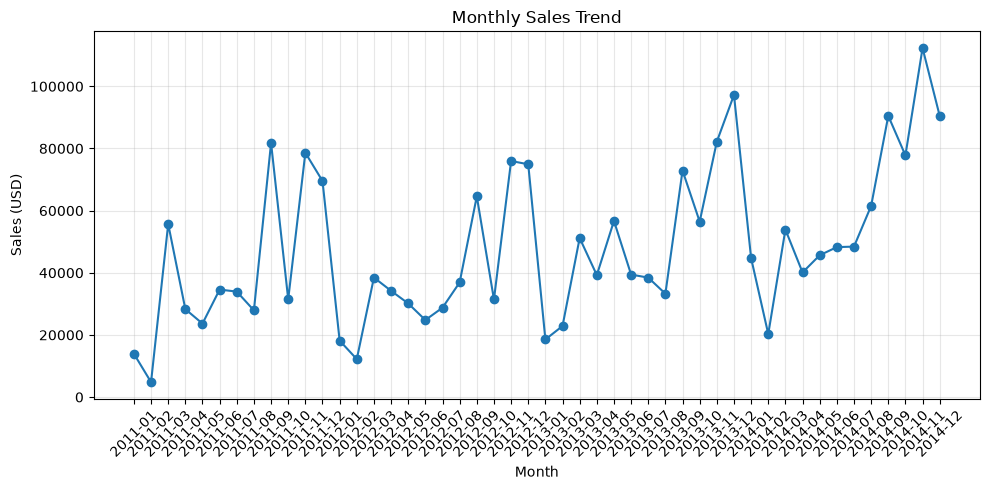

In [49]:
plt.figure(figsize=(10, 5))
plt.plot(
    monthly_sales.index.astype(str),
    monthly_sales.values,
    marker="o"
)
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales (USD)")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(output_dir / "monthly_sales_trend.png", dpi=300)
plt.show()

Sales peaked in November, indicating that this was the strongest month in the period analyzed.

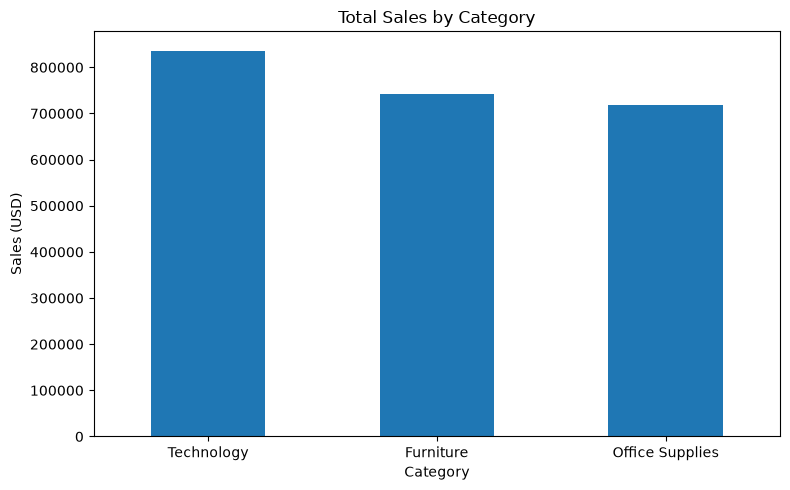

In [50]:
plt.figure(figsize=(8, 5))
sales_by_category.plot(kind="bar")
plt.title("Total Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales (USD)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(output_dir / "sales_by_category.png", dpi=300)
plt.show()

Technology recorded the highest total sales among all product categories.

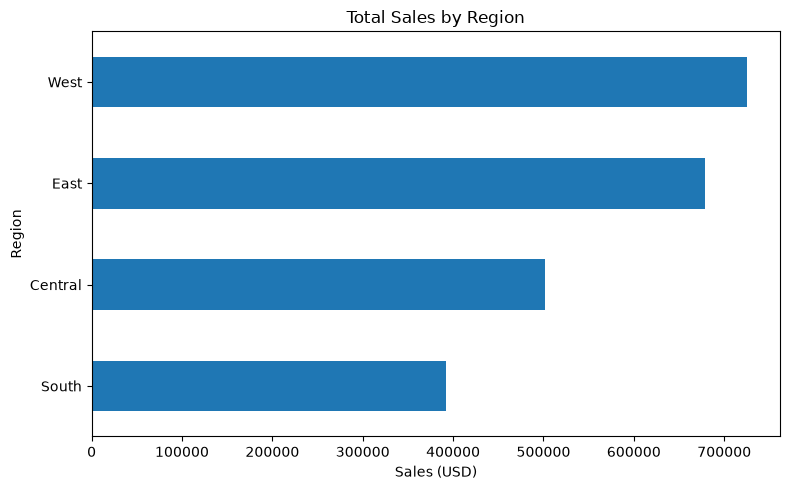

In [51]:
plt.figure(figsize=(8, 5))
sales_by_region.sort_values().plot(kind="barh")
plt.title("Total Sales by Region")
plt.xlabel("Sales (USD)")
plt.ylabel("Region")
plt.tight_layout()
plt.savefig(output_dir / "sales_by_region.png", dpi=300)
plt.show()

West generated the highest sales, making it the leading sales region in the dataset.

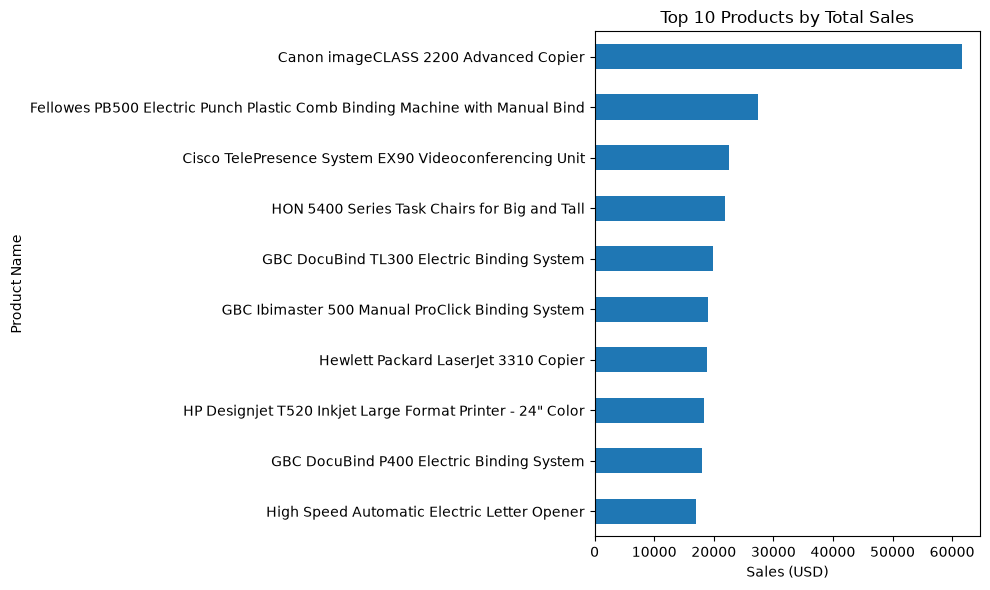

In [52]:
plt.figure(figsize=(10, 6))
top_10_products.sort_values().plot(kind="barh")
plt.title("Top 10 Products by Total Sales")
plt.xlabel("Sales (USD)")
plt.ylabel("Product Name")
plt.tight_layout()
plt.savefig(output_dir / "top_10_products.png", dpi=300)
plt.show()

Canon imageCLASS 2200 Advanced Copier generated the highest total sales among the top 10 products.

In [ ]:
df[(df["Discount"] < 0) | (df["Discount"] > 1)]

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,Month


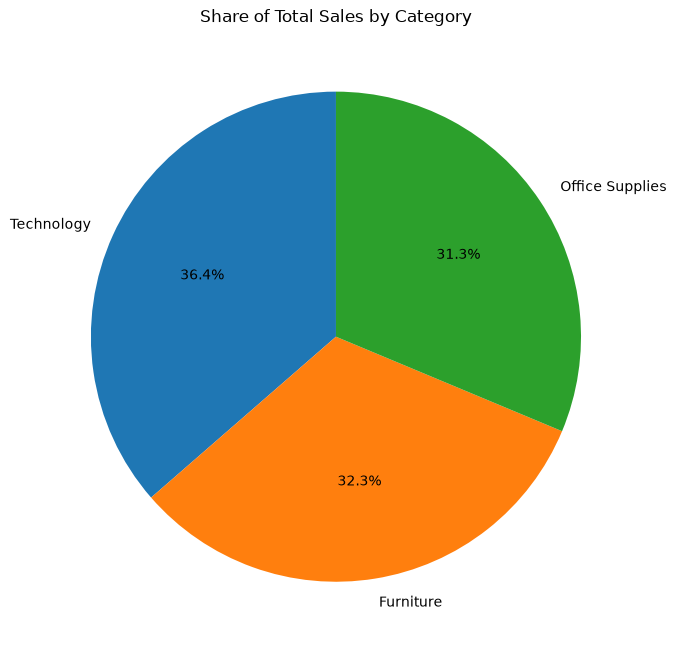

In [53]:
plt.figure(figsize=(7, 7))
sales_by_category.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Share of Total Sales by Category")
plt.ylabel("")
plt.tight_layout()
plt.savefig(output_dir / "sales_share_by_category.png", dpi=300)
plt.show()

Technology accounted for the largest share of total sales, contributing approximately 36.4% of the total.

In [54]:
print("Saved charts:")
for file in sorted(output_dir.glob("*.png")):
    print(file.name)

Saved charts:
monthly_sales_trend.png
sales_by_category.png
sales_by_region.png
sales_share_by_category.png
top_10_products.png


## Key Findings and Business Recommendations

### 1. Overall Performance
Summarize total sales, total profit, the number of unique orders, and average order value.

### 2. Monthly Sales Performance
Identify the highest- and lowest-sales months and describe any noticeable trends.

### 3. Category Performance
Identify the categories with the highest and lowest total sales.

### 4. Regional Performance
Identify the leading sales region and compare performance across regions.

### 5. Product Performance
Summarize the top-selling and lowest-selling products. Where relevant, compare sales with product profitability.

### 6. Business Recommendations
Recommend practical actions based on the findings, such as reviewing loss-making products, investigating discount strategies, and exploring opportunities in lower-performing regions.